# Checkpoint — Dimensie reductie

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `n_components_secom` — aantal PCA-componenten dat 95% van de variantie behoudt voor secom (int)
- `reduction_pct_secom` — procent datareductie voor SECOM (float)
- `X_pca_secom` — de gereduceerde data van SECOM (evenveel rijen als de oorspronkelijke data, `n_components_secom` kolommen)
- `n_components_steel` — aantal PCA-componenten dat 95% van de variantie behoudt voor Steel Plates (int)
- `reduction_pct_steel` — procent datareductie voor Steel Plates (float)
- `X_pca_steel` — de gereduceerde data van Steel Plates
- `n_components_aps` — aantal PCA-componenten dat 95% van de variantie behoudt voor APS (int)
- `reduction_pct_aps` — procent datareductie voor APS (float)
- `X_pca_aps` — de gereduceerde data van APS
- `antwoord_scaling` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_95` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik voor elke dataset `PCA(n_components=0.95)` op de **gestandaardiseerde** data (met `StandardScaler`). De datareductie bereken je als `(1 - aantal_componenten / oorspronkelijk_aantal_features) * 100`.

De datasets staan lokaal in `data/` (er wordt niets gedownload).


## Oefening 1 — SECOM

De SECOM-dataset bevat 590 sensormetingen van halfgeleiderproductie. Het bestand bevat veel ontbrekende waarden; vul ze in met het kolomgemiddelde.

Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_secom`, de gereduceerde data in `X_pca_secom` en de procentuele datareductie in `reduction_pct_secom`.


In [4]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/secom/secom.data"
labels_path = "data/secom/secom_labels.data"

# Dataset laden (spatie is de separator in SECOM)
X = pd.read_csv(data_path, sep="\\s+", header=None)
y = pd.read_csv(labels_path, sep="\\s+", header=None, usecols=[0])  # labels in eerste kolom

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [8]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_secom, de gereduceerde
# data in X_pca_secom en de procentuele datareductie in reduction_pct_secom.
pca = PCA(n_components=0.95, svd_solver='full', whiten=True)
X_pca_secom = pca.fit_transform(X_scaled)
n_components_secom = pca.n_components_
reduction_pct_secom = (1 - n_components_secom / X_scaled.shape[1]) * 100

print(f"Aantal componenten: {n_components_secom}")
print(f"Procentuele datareductie: {reduction_pct_secom:.2f}%")


Aantal componenten: 170
Procentuele datareductie: 71.19%


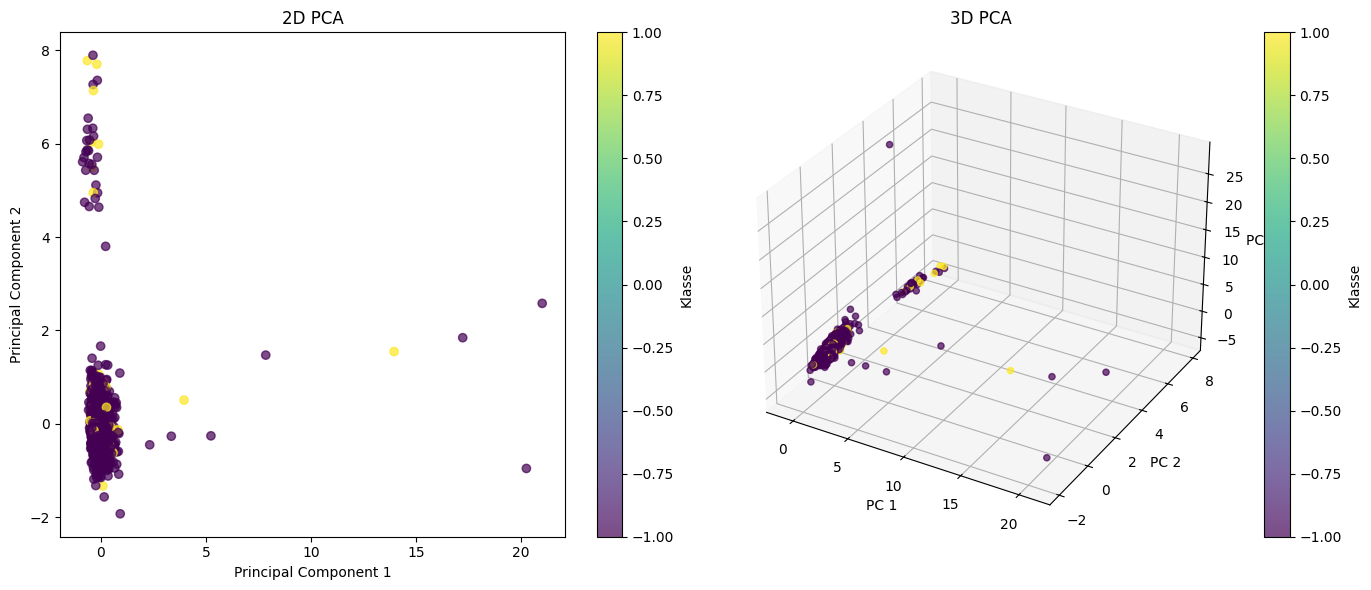

In [ ]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam). Tip: fit hiervoor opnieuw een
# PCA met n_components=2 en n_components=3 en kleur de punten met y.
pca_2 = PCA(n_components=2, svd_solver='full', whiten=True)
X_pca_2 = pca_2.fit_transform(X_scaled)
pca_3 = PCA(n_components=3, svd_solver='full', whiten=True)
X_pca_3 = pca_3.fit_transform(X_scaled)

# Maak met matplotlib één figuur met twee subplots naast elkaar (1 rij, 2 kolommen).
# Subplot 1 (2D): Maak een scatterplot. Zet kolom 0 van X_pca_2 op de x-as en kolom 1 op de y-as. Geef het de titel '2D PCA'.
# Subplot 2 (3D): Maak een 3D scatterplot. Zet kolom 0, 1 en 2 van X_pca_3 op respectievelijk de x-, y- en z-as. Geef het de titel '3D PCA'.
# Kleur en Legende: Gebruik de waarden uit dataframe y (y.values.flatten()) als argument voor 'c' om de punten in beide plots in te kleuren. Zorg in beide plots voor een duidelijke legende voor de klassen.

import matplotlib.pyplot as plt

# Figuur opzetten met 2 subplots (waarvan 1 in 3D)
fig = plt.figure(figsize=(14, 6))

# Flatten y zodat het als kleurenarray (1D) gebruikt kan worden
y_colors = y.values.flatten()

# --- 2D Plot ---
ax1 = fig.add_subplot(1, 2, 1)
scatter1 = ax1.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y_colors, cmap='viridis', alpha=0.7)
ax1.set_title('2D PCA')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')
fig.colorbar(scatter1, ax=ax1, label='Klasse')

# --- 3D Plot ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
scatter2 = ax2.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], c=y_colors, cmap='viridis', alpha=0.7)
ax2.set_title('3D PCA')
ax2.set_xlabel('PC 1')
ax2.set_ylabel('PC 2')
ax2.set_zlabel('PC 3')
fig.colorbar(scatter2, ax=ax2, label='Klasse')

plt.tight_layout()
plt.show()

## Oefening 2 — Steel Plates Faults

De Steel Plates Faults-dataset bevat 27 metingen van staalplaten. De kolomnamen staan in `data/steel_plates/Faults27x7_var`; de laatste 7 kolommen zijn binaire foutlabels.

Pas PCA toe zodat **95% van de variantie behouden blijft** op de 27 meetkolommen. Bewaar het aantal componenten in `n_components_steel`, de gereduceerde data in `X_pca_steel` en de procentuele datareductie in `reduction_pct_steel`.


In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/steel_plates/Faults.NNA"
names_path = "data/steel_plates/Faults27x7_var"

# Kolomnamen laden
with open(names_path, "r") as f:
    colnames = [line.strip() for line in f.readlines()]

# Data laden
df = pd.read_csv(data_path, sep="\\s+", header=None, names=colnames)

# Eerste 27 kolommen zijn de metingen, de laatste 7 zijn binaire foutlabels
X = df.iloc[:, :27]
y = df.iloc[:, 27:]

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [13]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_steel, de gereduceerde
# data in X_pca_steel en de procentuele datareductie in reduction_pct_steel.
pca = PCA(n_components=0.95, svd_solver='full', whiten=True)
X_pca_steel = pca.fit_transform(X_scaled)
n_components_steel = pca.n_components_
reduction_pct_steel = (1 - n_components_steel / X_scaled.shape[1]) * 100

print(f"Aantal componenten: {n_components_steel}")
print(f"Procentuele datareductie: {reduction_pct_steel:.2f}%")

Aantal componenten: 13
Procentuele datareductie: 51.85%


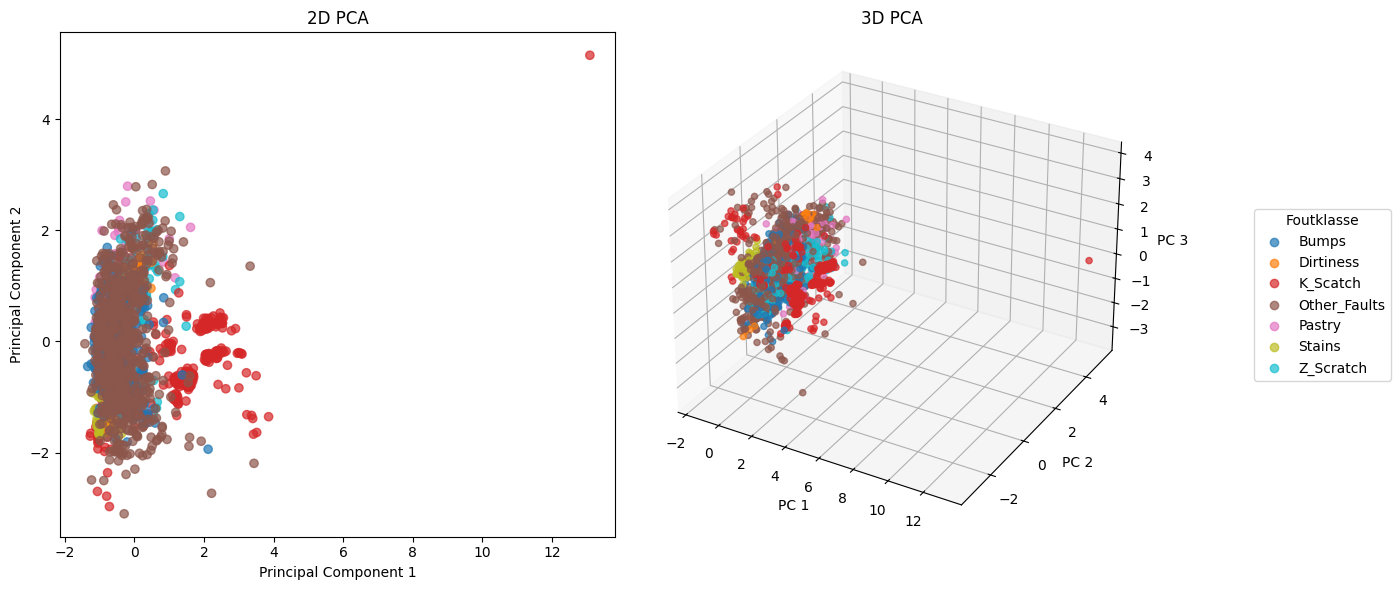

In [16]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam).
pca_2 = PCA(n_components=2, svd_solver='full', whiten=True)
X_pca_2 = pca_2.fit_transform(X_scaled)
pca_3 = PCA(n_components=3, svd_solver='full', whiten=True)
X_pca_3 = pca_3.fit_transform(X_scaled)

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Converteer de 7 binaire kolommen naar 1 kolom met de categorische naam (de kolomnaam waar de '1' staat)
y_categorical = y.idxmax(axis=1)

# Converteer de tekstlabels naar numerieke waarden voor matplotlib's 'c' argument
encoder = LabelEncoder()
y_numeric = encoder.fit_transform(y_categorical)

fig = plt.figure(figsize=(14, 6))

# --- 2D Plot ---
ax1 = fig.add_subplot(1, 2, 1)
scatter1 = ax1.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y_numeric, cmap='tab10', alpha=0.7)
ax1.set_title('2D PCA')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')

# --- 3D Plot ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
scatter2 = ax2.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], c=y_numeric, cmap='tab10', alpha=0.7)
ax2.set_title('3D PCA')
ax2.set_xlabel('PC 1')
ax2.set_ylabel('PC 2')
ax2.set_zlabel('PC 3')

# Maak een gedeelde legende voor beide plots
# We halen de unieke numerieke waardes en hun corresponderende naam op uit de encoder
handles, _ = scatter1.legend_elements()
fig.legend(handles, encoder.classes_, loc='center right', title="Foutklasse")

plt.tight_layout(rect=[0, 0, 0.85, 1]) # Ruimte maken voor de legende rechts
plt.show()

## Oefening 3 — APS Failure at Scania Trucks

De APS-dataset bevat 170 sensormetingen van vrachtwagens. De eerste 20 regels van de CSV-bestanden zijn metadata; de testset bevat geen labels.

Combineer train en test, vul ontbrekende waarden in en standaardiseer. Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_aps`, de gereduceerde data in `X_pca_aps` en de procentuele datareductie in `reduction_pct_aps`.


In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Train- en testdata laden (eerste 20 regels zijn metadata)
train = pd.read_csv("data/aps_failure/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("data/aps_failure/aps_failure_test_set.csv", skiprows=20, na_values="na")

X_train = train.drop(columns=["class"])
y_train = train["class"]
X_test = test.drop(columns=["class"])

# Combineer train + test voor de PCA (unsupervised setup)
X_all = pd.concat([X_train, X_test], ignore_index=True)

# Ontbrekende waarden invullen met het kolomgemiddelde
X_all = X_all.fillna(X_all.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)


In [18]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_aps, de gereduceerde
# data in X_pca_aps en de procentuele datareductie in reduction_pct_aps.
pca = PCA(n_components=0.95, svd_solver='full', whiten=True)
X_pca_aps = pca.fit_transform(X_scaled)
n_components_aps = pca.n_components_
reduction_pct_aps = (1 - n_components_aps / X_scaled.shape[1]) * 100

print(f"Aantal componenten: {n_components_aps}")
print(f"Procentuele datareductie: {reduction_pct_aps:.2f}%")

Aantal componenten: 83
Procentuele datareductie: 51.18%


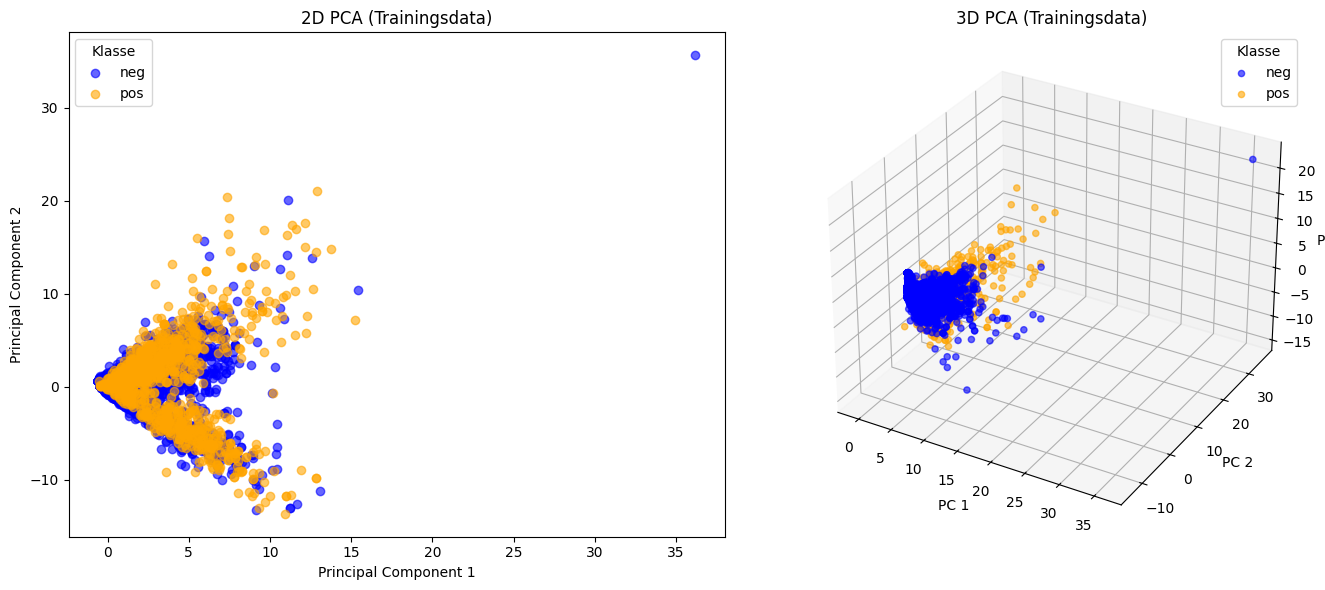

In [19]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van de
# trainingrijen van X_scaled (niet gecheckt, maar leerzaam).
pca_2 = PCA(n_components=2, svd_solver='full', whiten=True)
X_pca_2 = pca_2.fit_transform(X_scaled)
pca_3 = PCA(n_components=3, svd_solver='full', whiten=True)
X_pca_3 = pca_3.fit_transform(X_scaled)

import matplotlib.pyplot as plt

# Zet de figuur op met 1 rij en 2 kolommen
fig = plt.figure(figsize=(14, 6))

# Beperk de PCA data tot enkel de lengte van de trainingsset
X_pca_2_train = X_pca_2[:len(y_train)]
X_pca_3_train = X_pca_3[:len(y_train)]

# Bepaal de unieke klasses in y_train
classes = y_train.unique()
colors = ['blue', 'orange']  # Kies duidelijke kleuren

# --- Subplot 1: 2D Plot ---
ax1 = fig.add_subplot(1, 2, 1)
for cls, color in zip(classes, colors):
    # Selecteer enkel de rijen van deze specifieke klasse
    idx = (y_train == cls)
    ax1.scatter(X_pca_2_train[idx, 0], X_pca_2_train[idx, 1], c=color, label=cls, alpha=0.6)

ax1.set_title('2D PCA (Trainingsdata)')
ax1.set_xlabel('Principal Component 1')
ax1.set_ylabel('Principal Component 2')
ax1.legend(title='Klasse')

# --- Subplot 2: 3D Plot ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for cls, color in zip(classes, colors):
    # Selecteer enkel de rijen van deze specifieke klasse
    idx = (y_train == cls)
    ax2.scatter(X_pca_3_train[idx, 0], X_pca_3_train[idx, 1], X_pca_3_train[idx, 2], c=color, label=cls, alpha=0.6)

ax2.set_title('3D PCA (Trainingsdata)')
ax2.set_xlabel('PC 1')
ax2.set_ylabel('PC 2')
ax2.set_zlabel('PC 3')
ax2.legend(title='Klasse')

plt.tight_layout()
plt.show()

## Meerkeuzevragen

### Vraag 1 — Standaardiseren
Waarom moet je de features **standaardiseren** vóór je PCA toepast?

- **A)** Omdat PCA alleen werkt op gehele getallen.
- **B)** Omdat features op verschillende schalen anders onevenredig veel gewicht krijgen en de PCA dan vooral de grote schalen weerspiegelt.
- **C)** Omdat standaardiseren het aantal features vermindert.
- **D)** Omdat standaardiseren automatisch 95% van de variantie behoudt.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_scaling`.

### Vraag 2 — n_components=0.95
Wat betekent `PCA(n_components=0.95)`?

- **A)** Het model houdt 95 van de oorspronkelijke features over.
- **B)** Het model houdt 95% van de datapunten over.
- **C)** Het model kiest het kleinste aantal componenten dat samen minstens 95% van de variantie verklaart.
- **D)** Het model kiest altijd exact 95 componenten.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_95`.


In [20]:
# Vraag 1: antwoord_scaling = "A", "B", "C" of "D"
antwoord_scaling = "B"

# Vraag 2: antwoord_95 = "A", "B", "C" of "D"
antwoord_95 = "C"
